# Objective 2.2 — Predicting Goals Scored (Team-Match Level)

**Target:** goals scored by a team in a match (208 rows = 104 matches x 2 teams).

**8 explanatory variables (fixed by our plan, max 4 shared with Objective 2.1):**
1. Team FIFA ranking
2. Opponent Elo rating
3. Team average squad age
4. Opponent squad market value
5. Team previous average goals scored (pre-tournament only for a team's first WC match)
6. Team previous average shots
7. Team previous average shots on target
8. Opponent previous average saves

All "previous average" predictors use only information available *before* kickoff
(a `shift(1)` rolling average), so there is no data leakage from the match being predicted.


## 1. Load and validate the source data

In [ ]:
import pandas as pd
import numpy as np

features_df = pd.read_csv("match_prediction_features.csv")
matches_df = pd.read_csv("matches.csv")
stats_df = pd.read_csv("match_team_stats.csv")

print("Prediction features:", features_df.shape)
print("Matches:", matches_df.shape)
print("Team statistics:", stats_df.shape)

Prediction features: (104, 66)
Matches: (104, 17)
Team statistics: (208, 12)


In [ ]:
# Check that match IDs are unique and consistent between files
print("Feature match IDs unique:", features_df["match_id"].is_unique)
print("Matches match IDs unique:", matches_df["match_id"].is_unique)
print("Same match IDs:", set(features_df["match_id"]) == set(matches_df["match_id"]))

check_df = features_df[["match_id", "home_score", "away_score"]].merge(
    matches_df[["match_id", "home_score", "away_score"]],
    on="match_id", how="outer", suffixes=("_features", "_matches"),
    indicator=True, validate="one_to_one",
)
score_mismatch = (
    (check_df["_merge"] != "both")
    | (check_df["home_score_features"] != check_df["home_score_matches"])
    | (check_df["away_score_features"] != check_df["away_score_matches"])
)
print("Unmatched or inconsistent matches:", score_mismatch.sum())

Feature match IDs unique: True
Matches match IDs unique: True
Same match IDs: True
Unmatched or inconsistent matches: 0


In [ ]:
print("Total statistics rows:", len(stats_df))
print("Unique team-match records:",
      stats_df[["match_id", "team_id"]].drop_duplicates().shape[0])

team_counts = stats_df.groupby("match_id").size()
print("Matches with exactly two teams:", team_counts.eq(2).sum())
print("Total unique matches:", stats_df["match_id"].nunique())
print("Missing values in team stats:")
print(stats_df.isna().sum())

Total statistics rows: 208
Unique team-match records: 208
Matches with exactly two teams: 104
Total unique matches: 104
Missing values in team stats:
match_id                 0
team_id                  0
possession_pct           0
total_shots              0
shots_on_target          0
corners                  0
fouls                    0
offsides                 0
saves                    0
player_of_the_match    104
data_source              0
last_updated             0
dtype: int64


## 2. Reshape to one row per team per match

Each match becomes two rows: one from the home team's perspective, one from the
away team's. This gives the 208 rows the brief asks for.

In [ ]:
matches_df["date"] = pd.to_datetime(matches_df["date"], errors="coerce")

home = pd.DataFrame({
    "match_id": features_df["match_id"],
    "team_id": features_df["home_team_id"],
    "team": features_df["home_team_name"],
    "opponent": features_df["away_team_name"],
    "team_fifa_rank": features_df["home_fifa_rank"],
    "opponent_elo": features_df["away_elo"],
    "team_avg_age": features_df["home_squad_avg_age"],
    "opponent_squad_value": features_df["away_squad_total_value_eur"],
    "goals_scored": features_df["home_score"],
})

away = pd.DataFrame({
    "match_id": features_df["match_id"],
    "team_id": features_df["away_team_id"],
    "team": features_df["away_team_name"],
    "opponent": features_df["home_team_name"],
    "team_fifa_rank": features_df["away_fifa_rank"],
    "opponent_elo": features_df["home_elo"],
    "team_avg_age": features_df["away_squad_avg_age"],
    "opponent_squad_value": features_df["home_squad_total_value_eur"],
    "goals_scored": features_df["away_score"],
})

master_df = pd.concat([home, away], ignore_index=True)

master_df = master_df.merge(
    matches_df[["match_id", "date", "kickoff_time_utc"]],
    on="match_id", how="left", validate="many_to_one",
)
master_df = master_df.merge(
    stats_df[["match_id", "team_id", "total_shots", "shots_on_target", "saves"]],
    on=["match_id", "team_id"], how="left", validate="one_to_one",
)

print("Dataset shape:", master_df.shape)
master_df.head()

Dataset shape: (208, 14)


,match_id,team_id,team,opponent,team_fifa_rank,opponent_elo,team_avg_age,opponent_squad_value,goals_scored,date,kickoff_time_utc,total_shots,shots_on_target,saves
0,1,1,Mexico,South Africa,14,1620.0,27.900700,47700000.0,2,2026-06-11,19:00,16,4,1
1,2,3,South Korea,Czechia,22,1740.0,28.065708,187141830.0,2,2026-06-11,23:00,12,5,2
2,3,5,Canada,Bosnia and Herzegovina,33,1645.0,26.972674,146400000.0,1,2026-06-12,19:00,13,4,3
3,4,13,USA,Paraguay,17,1725.0,26.904965,135683726.0,4,2026-06-12,23:00,16,6,1
4,5,7,Qatar,Switzerland,56,1860.0,29.507713,357184518.0,1,2026-06-13,15:00,6,3,4


## 3. Chronological ordering and pre-match rolling averages



In [ ]:
# Build one correct chronological ordering: date + kickoff time
master_df["kickoff_datetime"] = pd.to_datetime(
    master_df["date"].dt.strftime("%Y-%m-%d") + " " + master_df["kickoff_time_utc"].astype(str),
    format="%Y-%m-%d %H:%M", utc=True,
)
master_df = master_df.sort_values(["kickoff_datetime", "match_id", "team_id"]).reset_index(drop=True)

print("Duplicate kickoff timestamps:", master_df["kickoff_datetime"].duplicated().sum())
print("Unparseable kickoff values:", master_df["kickoff_datetime"].isna().sum())

Duplicate kickoff timestamps: 118
Unparseable kickoff values: 0


In [ ]:
# Pre-match rolling averages: shift(1) first, so the current match is never
# included in its own "previous average"
roll_cols = {
    "goals_scored": "team_prev_avg_goals_scored",
    "total_shots": "team_prev_avg_shots",
    "shots_on_target": "team_prev_avg_shots_on_target",
    "saves": "team_prev_avg_saves",
}
for src, new in roll_cols.items():
    master_df[new] = (
        master_df.groupby("team_id")[src]
        .transform(lambda s: s.shift(1).rolling(window=5, min_periods=1).mean())
    )

# Map each team to its opponent in the same match, to get opponent_prev_avg_saves
team_pairs = master_df[["match_id", "team_id"]].merge(
    master_df[["match_id", "team_id"]].rename(columns={"team_id": "opponent_team_id"}),
    on="match_id",
)
team_pairs = team_pairs[team_pairs["team_id"] != team_pairs["opponent_team_id"]]

opponent_saves = master_df[["match_id", "team_id", "team_prev_avg_saves"]].rename(
    columns={"team_id": "opponent_team_id", "team_prev_avg_saves": "opponent_prev_avg_saves"}
)
team_pairs = team_pairs.merge(opponent_saves, on=["match_id", "opponent_team_id"], how="left")

master_df = master_df.merge(
    team_pairs[["match_id", "team_id", "opponent_prev_avg_saves"]],
    on=["match_id", "team_id"], how="left", validate="one_to_one",
)

print("Historical averages calculated using the corrected chronological order.")

Historical averages calculated using the corrected chronological order.


## 4. Assemble the 8-predictor master dataset

In [ ]:
predictors = [
    "team_fifa_rank",
    "opponent_elo",
    "team_avg_age",
    "opponent_squad_value",
    "team_prev_avg_goals_scored",
    "team_prev_avg_shots",
    "team_prev_avg_shots_on_target",
    "opponent_prev_avg_saves",
]

final_columns = (
    ["match_id", "team_id", "team", "opponent", "kickoff_datetime"]
    + predictors + ["goals_scored"]
)
regression_master = master_df[final_columns].copy()

assert len(regression_master) == 208
assert regression_master["match_id"].nunique() == 104
assert len(predictors) == 8
assert regression_master.groupby("match_id").size().eq(2).all()

print("Master dataset shape:", regression_master.shape)
print("Number of predictors:", len(predictors))
print("\nMissing values before pre-tournament fallback:")
print(regression_master[predictors].isna().sum())

Master dataset shape: (208, 14)
Number of predictors: 8

Missing values before pre-tournament fallback:
team_fifa_rank                    0
opponent_elo                      0
team_avg_age                      0
opponent_squad_value              0
team_prev_avg_goals_scored       48
team_prev_avg_shots              48
team_prev_avg_shots_on_target    48
opponent_prev_avg_saves          48
dtype: int64


## 5. Fill each team's opening-match gap with real pre-tournament form



In [ ]:
history_df = pd.read_csv("results.csv")
history_df["date"] = pd.to_datetime(history_df["date"], errors="coerce")

wc_teams = set(regression_master["team"].unique())
historical_teams = set(history_df["home_team"]) | set(history_df["away_team"])
unmatched = sorted(wc_teams - historical_teams)
print("World Cup teams:", len(wc_teams))
print("Teams with different names in the historical dataset:", len(unmatched))
print(unmatched)

World Cup teams: 48
Teams with different names in the historical dataset: 7
['Cabo Verde', 'Congo DR', 'Czechia', "Côte d'Ivoire", 'IR Iran', 'Türkiye', 'USA']


In [ ]:
# Map World Cup team names to the historical dataset's naming
name_mapping = {
    "Cabo Verde": "Cape Verde",
    "Congo DR": "DR Congo",
    "Czechia": "Czech Republic",
    "C\u00f4te d'Ivoire": "Ivory Coast",
    "IR Iran": "Iran",
    "T\u00fcrkiye": "Turkey",
    "USA": "United States",
}
regression_master["historical_team"] = regression_master["team"].replace(name_mapping)

still_unmatched = set(regression_master["historical_team"]) - historical_teams
print("Unmatched teams remaining:", len(still_unmatched))

Unmatched teams remaining: 0


In [ ]:
# Pre-tournament form: each team's average goals over its last 5 matches
# strictly before the World Cup started
cutoff_date = pd.Timestamp("2026-06-11")
past_matches = history_df[history_df["date"] < cutoff_date].copy()

home_hist = past_matches[["date", "home_team", "home_score"]].rename(
    columns={"home_team": "team", "home_score": "goals_scored"})
away_hist = past_matches[["date", "away_team", "away_score"]].rename(
    columns={"away_team": "team", "away_score": "goals_scored"})
team_history = pd.concat([home_hist, away_hist], ignore_index=True).sort_values("date")

pretournament_avg_goals = (
    team_history.groupby("team").tail(5).groupby("team")["goals_scored"].mean()
)

regression_master["pre_tournament_avg_goals"] = (
    regression_master["historical_team"].map(pretournament_avg_goals)
)
regression_master["team_prev_avg_goals_scored"] = (
    regression_master["team_prev_avg_goals_scored"]
    .fillna(regression_master["pre_tournament_avg_goals"])
)

print("Missing values after pre-tournament fallback:")
print(regression_master[predictors].isna().sum())

regression_master = regression_master.drop(columns=["historical_team", "pre_tournament_avg_goals"])
regression_master.to_csv("regression_2_2_master.csv", index=False)
print("\nFinal master dataset:", regression_master.shape)

Missing values after pre-tournament fallback:
team_fifa_rank                    0
opponent_elo                      0
team_avg_age                      0
opponent_squad_value              0
team_prev_avg_goals_scored        0
team_prev_avg_shots              48
team_prev_avg_shots_on_target    48
opponent_prev_avg_saves          48
dtype: int64

Final master dataset: (208, 14)


## 6. Exploratory data analysis



In [ ]:
X_all = regression_master[predictors].copy()
y_all = regression_master["goals_scored"].copy()

eda_summary = regression_master[["goals_scored"] + predictors].describe().T
eda_summary.round(2)

,count,mean,std,min,25%,50%,75%,max
goals_scored,208.0,1.480000e+00,1.390000e+00,0.00,0.000000e+00,1.000000e+00,2.000000e+00,7.000000e+00
team_fifa_rank,208.0,2.826000e+01,2.294000e+01,1.00,8.750000e+00,2.250000e+01,4.425000e+01,8.500000e+01
opponent_elo,208.0,1.839470e+03,1.679400e+02,1510.00,1.720000e+03,1.817500e+03,1.970000e+03,2.150000e+03
team_avg_age,208.0,2.787000e+01,1.090000e+00,25.85,2.697000e+01,2.765000e+01,2.861000e+01,3.043000e+01
opponent_squad_value,208.0,5.134707e+08,5.147272e+08,37905696.00,1.454358e+08,3.571845e+08,6.340660e+08,2.134173e+09
team_prev_avg_goals_scored,208.0,1.730000e+00,1.040000e+00,0.00,1.000000e+00,1.780000e+00,2.330000e+00,7.000000e+00
team_prev_avg_shots,160.0,1.310000e+01,4.950000e+00,3.00,9.750000e+00,1.250000e+01,1.585000e+01,3.100000e+01
team_prev_avg_shots_on_target,160.0,4.700000e+00,2.330000e+00,0.50,3.000000e+00,4.670000e+00,6.670000e+00,1.200000e+01
opponent_prev_avg_saves,160.0,3.170000e+00,1.840000e+00,0.67,2.000000e+00,2.500000e+00,4.000000e+00,1.000000e+01


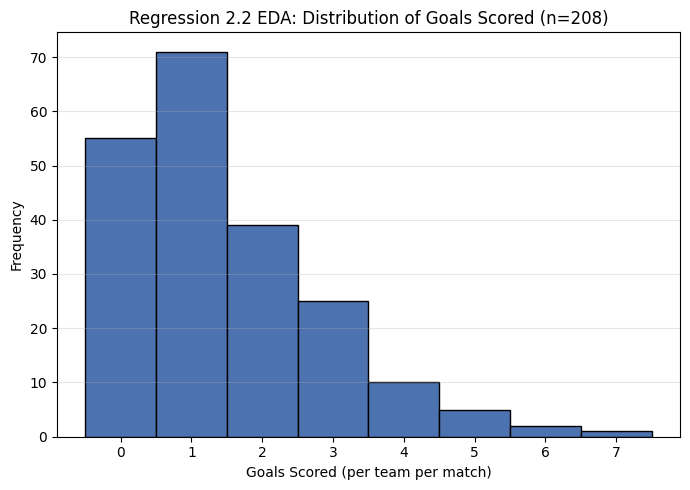

Mean: 1.48  Median: 1.0  Std: 1.39  Max: 7
Goals scored is right-skewed and count-like (a lot of 0s and 1s, a long tail) --
worth keeping in mind since OLS/Ridge assume a roughly continuous, symmetric target.


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.hist(y_all, bins=range(0, int(y_all.max()) + 2), color="#4C72B0", edgecolor="black", align="left")
plt.xlabel("Goals Scored (per team per match)")
plt.ylabel("Frequency")
plt.title("Regression 2.2 EDA: Distribution of Goals Scored (n=208)")
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig("eda_target_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Mean: {y_all.mean():.2f}  Median: {y_all.median():.1f}  Std: {y_all.std():.2f}  Max: {y_all.max()}")
print("Goals scored is right-skewed and count-like (a lot of 0s and 1s, a long tail) --")
print("worth keeping in mind since OLS/Ridge assume a roughly continuous, symmetric target.")

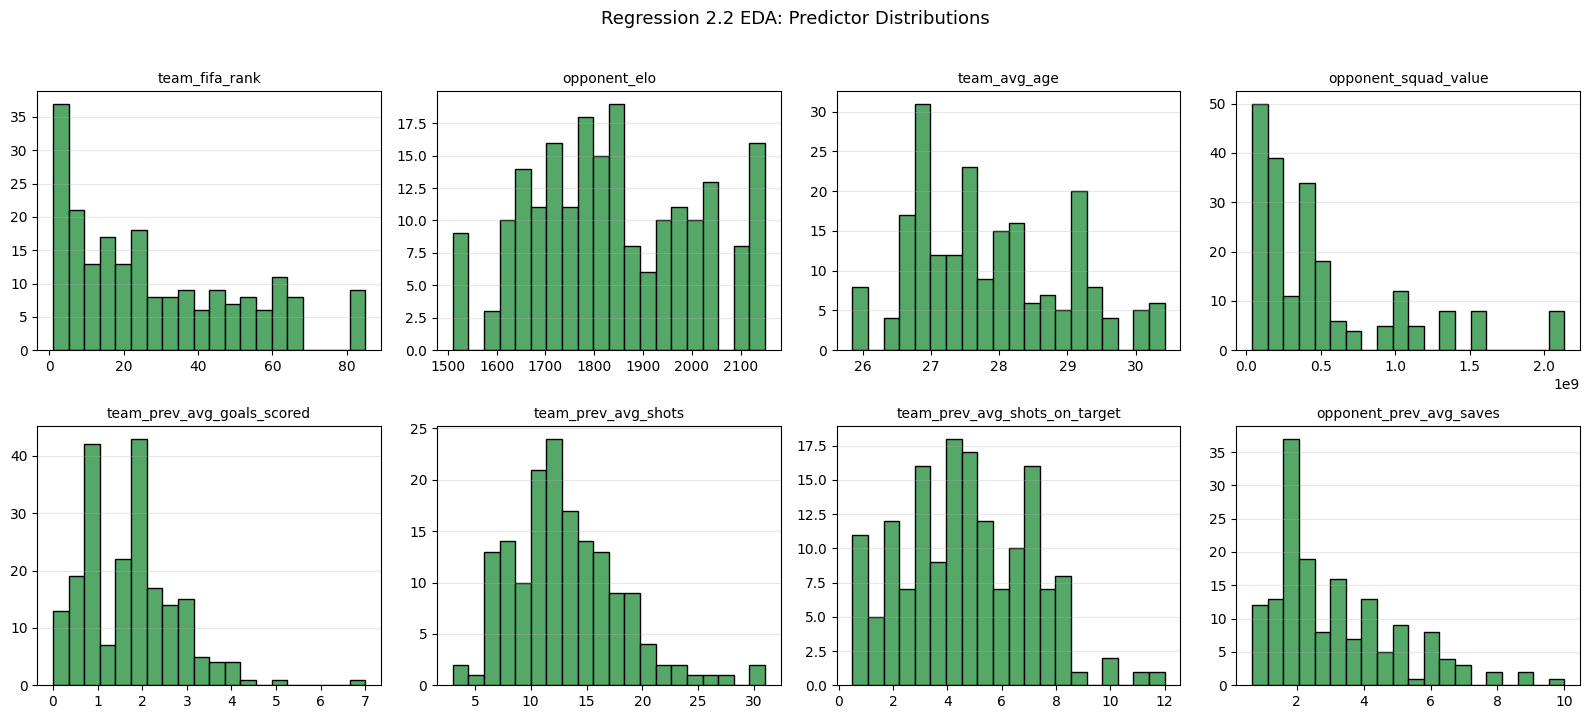

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, predictors):
    ax.hist(X_all[col].dropna(), bins=20, color="#55A868", edgecolor="black")
    ax.set_title(col, fontsize=10)
    ax.grid(alpha=0.3, axis="y")
plt.suptitle("Regression 2.2 EDA: Predictor Distributions", y=1.02, fontsize=13)
plt.tight_layout()
plt.savefig("eda_predictor_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

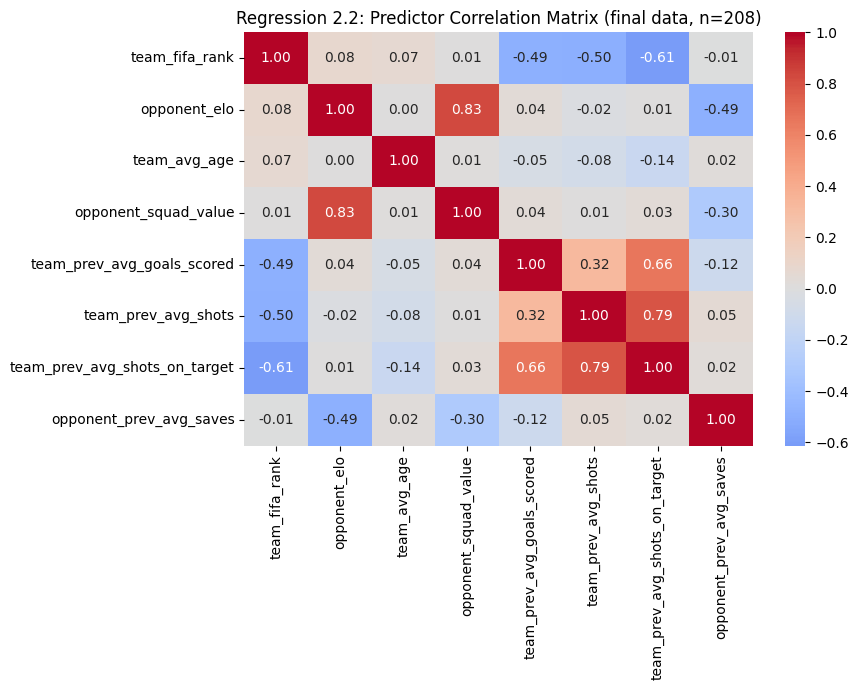

opponent_elo vs opponent_squad_value: r = 0.83
team_prev_avg_shots vs team_prev_avg_shots_on_target: r = 0.79


In [ ]:
import seaborn as sns

plt.figure(figsize=(9, 7))
correlation_matrix = X_all.corr()
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Regression 2.2: Predictor Correlation Matrix (final data, n=208)")
plt.tight_layout()
plt.savefig("regression_2_2_correlation.png", dpi=300, bbox_inches="tight")
plt.show()

elo_value_corr = correlation_matrix.loc["opponent_elo", "opponent_squad_value"]
shots_corr = correlation_matrix.loc["team_prev_avg_shots", "team_prev_avg_shots_on_target"]
print(f"opponent_elo vs opponent_squad_value: r = {elo_value_corr:.2f}")
print(f"team_prev_avg_shots vs team_prev_avg_shots_on_target: r = {shots_corr:.2f}")

## 7. Train/test split (chronological, 80/20, both rows of a match kept together)

In [ ]:
X = regression_master[predictors].copy()
y = regression_master["goals_scored"].copy()
groups = regression_master["match_id"].copy()

match_order = regression_master[["match_id", "kickoff_datetime"]].drop_duplicates().sort_values(
    ["kickoff_datetime", "match_id"]
)
match_ids_sorted = match_order["match_id"].to_numpy()
split_point = int(len(match_ids_sorted) * 0.8)
train_ids = match_ids_sorted[:split_point]
test_ids = match_ids_sorted[split_point:]

train_mask = regression_master["match_id"].isin(train_ids)
test_mask = regression_master["match_id"].isin(test_ids)

X_train, X_test = X.loc[train_mask], X.loc[test_mask]
y_train, y_test = y.loc[train_mask], y.loc[test_mask]

print("Training matches:", len(train_ids), " Testing matches:", len(test_ids))
print("Training rows:", len(X_train), " Testing rows:", len(X_test))
print("Matches shared between sets:", len(set(train_ids) & set(test_ids)))

Training matches: 83  Testing matches: 21
Training rows: 166  Testing rows: 42
Matches shared between sets: 0


## 8. Grouped 10-fold cross-validation



In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def make_pipeline(alpha=1.0, model="ridge"):
    reg = Ridge(alpha=alpha) if model == "ridge" else LinearRegression()
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regression", reg),
    ])

gkf = GroupKFold(n_splits=10)

def grouped_cv_scores(pipe, X, y, groups, gkf):
    preds = cross_val_predict(pipe, X, y, groups=groups, cv=gkf)
    rmse = np.sqrt(mean_squared_error(y, preds))
    mae = mean_absolute_error(y, preds)
    r2 = r2_score(y, preds)
    return mae, rmse, r2, preds

# Baseline: predict the mean of each fold's TRAINING matches (same folds as the models)
baseline_preds_cv = np.zeros(len(y))
for tr_idx, te_idx in gkf.split(X, y, groups):
    baseline_preds_cv[te_idx] = y.iloc[tr_idx].mean()
baseline_cv_rmse = np.sqrt(mean_squared_error(y, baseline_preds_cv))
baseline_cv_mae = mean_absolute_error(y, baseline_preds_cv)
baseline_cv_r2 = r2_score(y, baseline_preds_cv)

ols_mae_cv, ols_rmse_cv, ols_r2_cv, _ = grouped_cv_scores(make_pipeline(model="ols"), X, y, groups, gkf)
ridge_mae_cv, ridge_rmse_cv, ridge_r2_cv, _ = grouped_cv_scores(make_pipeline(alpha=1.0, model="ridge"), X, y, groups, gkf)

cv_results = pd.DataFrame({
    "Model": ["Baseline (training-fold mean)", "OLS (grouped 10-fold CV)", "Ridge alpha=1.0 (grouped 10-fold CV)"],
    "MAE": [baseline_cv_mae, ols_mae_cv, ridge_mae_cv],
    "RMSE": [baseline_cv_rmse, ols_rmse_cv, ridge_rmse_cv],
    "R2": [baseline_cv_r2, ols_r2_cv, ridge_r2_cv],
})
cv_results.to_csv("regression_2_2_cv_results.csv", index=False)
print("10-fold match-grouped cross-validation (full 208-row dataset):")
cv_results.round(3)

10-fold match-grouped cross-validation (full 208-row dataset):


,Model,MAE,RMSE,R2
0,Baseline (training-fold mean),1.115,1.394,-0.005
1,OLS (grouped 10-fold CV),0.955,1.254,0.186
2,Ridge alpha=1.0 (grouped 10-fold CV),0.955,1.254,0.186


## 9. Ridge alpha tuning



In [ ]:
alphas = [0.01, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0]
tuning_rows = []
for a in alphas:
    mae_a, rmse_a, r2_a, _ = grouped_cv_scores(make_pipeline(alpha=a, model="ridge"), X, y, groups, gkf)
    tuning_rows.append({"alpha": a, "MAE": mae_a, "RMSE": rmse_a, "R2": r2_a})

tuning_df = pd.DataFrame(tuning_rows)
tuning_df.to_csv("regression_2_2_ridge_tuning.csv", index=False)
best_alpha = tuning_df.loc[tuning_df["RMSE"].idxmin(), "alpha"]
print("Best alpha by CV RMSE:", best_alpha)
tuning_df.round(3)

Best alpha by CV RMSE: 30.0


,alpha,MAE,RMSE,R2
0,0.01,0.955,1.254,0.186
1,0.10,0.955,1.254,0.186
2,0.30,0.955,1.254,0.186
3,1.00,0.955,1.254,0.186
4,3.00,0.954,1.253,0.187
5,10.00,0.953,1.251,0.190
6,30.00,0.951,1.251,0.190
7,100.00,0.958,1.258,0.180


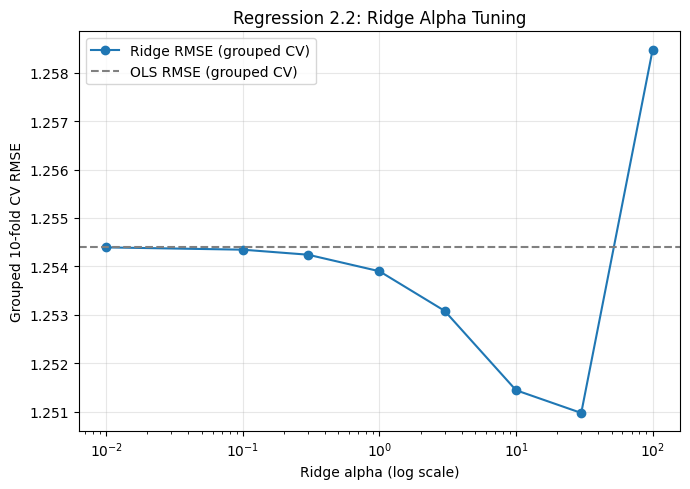

In [ ]:
plt.figure(figsize=(7, 5))
plt.plot(tuning_df["alpha"], tuning_df["RMSE"], marker="o", label="Ridge RMSE (grouped CV)")
plt.axhline(ols_rmse_cv, color="gray", linestyle="--", label="OLS RMSE (grouped CV)")
plt.xscale("log")
plt.xlabel("Ridge alpha (log scale)")
plt.ylabel("Grouped 10-fold CV RMSE")
plt.title("Regression 2.2: Ridge Alpha Tuning")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("regression_2_2_alpha_tuning.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Final hold-out model, OLS comparison, coefficients and VIF

Fit on the chronological 80/20 split, compared against OLS and the
mean-prediction baseline. We then refit with `statsmodels` to get p-values,
confidence intervals and variance inflation factors.

In [ ]:
# Alpha chosen by grouped-CV tuning
chosen_alpha = float(best_alpha)
model = make_pipeline(alpha=chosen_alpha, model="ridge")
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

baseline_pred = np.full(len(y_test), y_train.mean())
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

ols_holdout = make_pipeline(model="ols")
ols_holdout.fit(X_train, y_train)
y_pred_ols = ols_holdout.predict(X_test)
ols_mae = mean_absolute_error(y_test, y_pred_ols)
ols_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ols))
ols_r2 = r2_score(y_test, y_pred_ols)

comparison = pd.DataFrame({
    "Model": ["Baseline (train mean)", "OLS (holdout)", f"Ridge alpha={chosen_alpha} (holdout)"],
    "MAE": [baseline_mae, ols_mae, mae],
    "RMSE": [baseline_rmse, ols_rmse, rmse],
    "R2": [baseline_r2, ols_r2, r2],
})
comparison.to_csv("regression_2_2_model_results.csv", index=False)
print("FINAL HOLD-OUT RESULTS (chronological 80/20 split)")
comparison.round(3)

FINAL HOLD-OUT RESULTS (chronological 80/20 split)


,Model,MAE,RMSE,R2
0,Baseline (train mean),1.045,1.315,-0.002
1,OLS (holdout),0.957,1.294,0.030
2,Ridge alpha=30.0 (holdout),0.950,1.291,0.035


### Why the hold-out R² (0.03) is lower than the cross-validated R² (0.19)
The hold-out contains only the **21 latest matches** (late Round of 32 to the Final), so it is small and not representative of the whole
tournament. Cross-validation uses all 104 matches in ten different splits and is therefore the more reliable estimate; the hold-out is
reported as a check that respects time order, but it should be read as indicative only.

In [ ]:
stage_names = {1: "Group Stage", 2: "Round of 32", 3: "Round of 16", 4: "Quarter-finals",
               5: "Semi-finals", 6: "Third-place match", 7: "Final"}
test_stage = (matches_df.loc[matches_df["match_id"].isin(test_ids), "stage_id"]
              .map(stage_names).value_counts())
print("Stage of the 21 hold-out matches:")
print(test_stage.to_string())
print(f"\nGoals per team - train: mean {y_train.mean():.2f}, sd {y_train.std():.2f} | "
      f"hold-out: mean {y_test.mean():.2f}, sd {y_test.std():.2f}")
print(f"Hold-out size: {len(test_ids)} matches / {len(y_test)} rows")

Stage of the 21 hold-out matches:
stage_id
Round of 16          8
Round of 32          5
Quarter-finals       4
Semi-finals          2
Third-place match    1
Final                1

Goals per team - train: mean 1.47, sd 1.41 | hold-out: mean 1.52, sd 1.33
Hold-out size: 21 matches / 42 rows


In [ ]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_train_sm = X_train.fillna(X_train.median()).copy()
X_train_sm["opponent_squad_value"] = X_train_sm["opponent_squad_value"] / 1e6
X_train_const = sm.add_constant(X_train_sm)
train_groups = groups.loc[X_train.index]

ols_classical = sm.OLS(y_train, X_train_const).fit()
ols_sm = sm.OLS(y_train, X_train_const).fit(
    cov_type="cluster", cov_kwds={"groups": train_groups})
print(ols_sm.summary())
print(f"\nOverall F-test (classical): F = {ols_classical.fvalue:.2f}, p = {ols_classical.f_pvalue:.2e}; "
      f"R2 = {ols_classical.rsquared:.3f}, adj R2 = {ols_classical.rsquared_adj:.3f}")

ci = ols_sm.conf_int()
inference_df = pd.DataFrame({
    "coefficient": ols_sm.params, "cluster_se": ols_sm.bse, "p_value": ols_sm.pvalues,
    "ci_low": ci[0], "ci_high": ci[1],
})
inference_df.to_csv("regression_2_2_ols_inference.csv")
inference_df.round(4)

                            OLS Regression Results                            
Dep. Variable:           goals_scored   R-squared:                       0.283
Model:                            OLS   Adj. R-squared:                  0.246
Method:                 Least Squares   F-statistic:                     9.786
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           1.94e-09
Time:                        12:34:47   Log-Likelihood:                -264.83
No. Observations:                 166   AIC:                             547.7
Df Residuals:                     157   BIC:                             575.7
Df Model:                           8                                         
Covariance Type:              cluster                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

,coefficient,cluster_se,p_value,ci_low,ci_high
const,11.4804,3.4535,0.0009,4.7118,18.2491
team_fifa_rank,-0.0183,0.0051,0.0003,-0.0283,-0.0084
opponent_elo,-0.0036,0.0013,0.0042,-0.0061,-0.0011
team_avg_age,-0.1008,0.0756,0.1828,-0.2490,0.0475
opponent_squad_value,0.0001,0.0003,0.7436,-0.0005,0.0007
team_prev_avg_goals_scored,-0.0372,0.1279,0.7709,-0.2879,0.2134
team_prev_avg_shots,-0.0153,0.0396,0.6986,-0.0930,0.0623
team_prev_avg_shots_on_target,0.0407,0.1020,0.6898,-0.1593,0.2407
opponent_prev_avg_saves,-0.0256,0.0614,0.6765,-0.1459,0.0947


In [ ]:
vif_data = pd.DataFrame()
vif_data["Predictor"] = predictors
vif_data["VIF"] = [
    variance_inflation_factor(X_train_const[["const"] + predictors].values, i + 1)
    for i in range(len(predictors))
]
vif_data.to_csv("regression_2_2_vif.csv", index=False)
print("Variance Inflation Factors (training data):")
vif_data.round(2)

Variance Inflation Factors (training data):


,Predictor,VIF
0,team_fifa_rank,1.51
1,opponent_elo,3.51
2,team_avg_age,1.02
3,opponent_squad_value,3.11
4,team_prev_avg_goals_scored,2.00
5,team_prev_avg_shots,2.95
6,team_prev_avg_shots_on_target,4.17
7,opponent_prev_avg_saves,1.24


## 11. Diagnostic plots

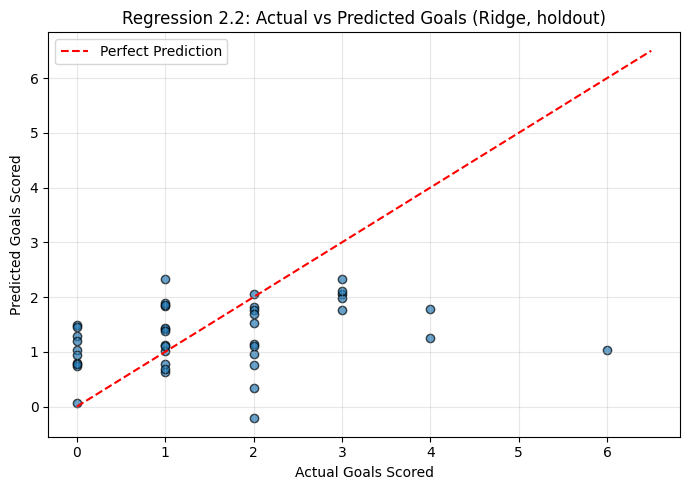

In [ ]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.7, edgecolors="black")
limit = max(y_test.max(), y_pred.max()) + 0.5
plt.plot([0, limit], [0, limit], "r--", label="Perfect Prediction")
plt.xlabel("Actual Goals Scored")
plt.ylabel("Predicted Goals Scored")
plt.title("Regression 2.2: Actual vs Predicted Goals (Ridge, holdout)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("regression_2_2_actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.7, edgecolors="black")
plt.axhline(0, color="red", linestyle="--", label="Zero Error")
plt.xlabel("Predicted Goals")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Regression 2.2: Residual Analysis (Ridge, holdout)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("regression_2_2_residuals.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
from scipy import stats as sps

plt.figure(figsize=(6, 6))
sps.probplot(residuals, dist="norm", plot=plt)
plt.title("Regression 2.2: Normal Q-Q Plot of Residuals (holdout)")
plt.tight_layout()
plt.savefig("regression_2_2_qqplot.png", dpi=300, bbox_inches="tight")
plt.show()

## 12. Predictor coefficients

In [ ]:
coef_df = pd.DataFrame({
    "Predictor": predictors,
    "Coefficient": model.named_steps["regression"].coef_,
})
coef_df["Absolute_Importance"] = coef_df["Coefficient"].abs()
coef_df_sorted = coef_df.sort_values("Absolute_Importance", ascending=False)
coef_df_sorted.to_csv("regression_2_2_coefficients.csv", index=False)
print("REGRESSION 2.2 - PREDICTOR COEFFICIENTS (standardized Ridge, final model)")
coef_df_sorted.round(4)

In [ ]:
coef_plot_df = coef_df.sort_values("Coefficient")
colors = ["steelblue" if v > 0 else "tomato" for v in coef_plot_df["Coefficient"]]

plt.figure(figsize=(9, 5))
plt.barh(coef_plot_df["Predictor"], coef_plot_df["Coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Standardized Ridge Coefficient")
plt.ylabel("Explanatory Variables")
plt.title("Regression 2.2: Influence of Eight Predictors")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("regression_2_2_predictor_coefficients.png", dpi=300, bbox_inches="tight")
plt.show()

## 13. Feature-engineering check: shots vs. shots-on-target



In [ ]:
X_eng = X.copy()
X_eng["team_prev_shot_accuracy"] = (
    X_eng["team_prev_avg_shots_on_target"] / X_eng["team_prev_avg_shots"].replace(0, np.nan)
)
eng_predictors = [p for p in predictors if p != "team_prev_avg_shots"] + ["team_prev_shot_accuracy"]
X_eng_final = X_eng[eng_predictors]

eng_mae, eng_rmse, eng_r2, _ = grouped_cv_scores(make_pipeline(alpha=1.0, model="ridge"), X_eng_final, y, groups, gkf)

eng_results = pd.DataFrame({
    "Model": ["Original 8 variables (submitted)", "team_prev_avg_shots -> shot-accuracy ratio"],
    "MAE": [ridge_mae_cv, eng_mae],
    "RMSE": [ridge_rmse_cv, eng_rmse],
    "R2": [ridge_r2_cv, eng_r2],
})
eng_results.to_csv("regression_2_2_feature_engineering_check.csv", index=False)
eng_results.round(3)

The shot-accuracy variant is marginally better (RMSE 1.249 vs. 1.254, R²
0.193 vs. 0.186) but the difference is small enough to be noise at n=208.

## 14. Save outputs

In [ ]:
regression_master[
    ["match_id", "team_id", "team", "opponent"] + predictors + ["goals_scored"]
].to_csv("regression_2_2_final_dataset.csv", index=False)

print("Files saved successfully!")

In [ ]:
import os
import zipfile

files_to_download = [
    "match_prediction_features.csv",
    "matches.csv",
    "match_team_stats.csv",
    "results.csv",
    "regression_2_2_final_dataset.csv",
    "regression_2_2_model_results.csv",
    "regression_2_2_cv_results.csv",
    "regression_2_2_ridge_tuning.csv",
    "regression_2_2_vif.csv",
    "regression_2_2_ols_inference.csv",
    "regression_2_2_coefficients.csv",
    "regression_2_2_feature_engineering_check.csv",
    "eda_target_distribution.png",
    "eda_predictor_distributions.png",
    "regression_2_2_correlation.png",
    "regression_2_2_alpha_tuning.png",
    "regression_2_2_actual_vs_predicted.png",
    "regression_2_2_residuals.png",
    "regression_2_2_qqplot.png",
    "regression_2_2_predictor_coefficients.png",
]

notebooks = [f for f in os.listdir(".") if f.endswith(".ipynb") and not f.startswith(".")]
files_to_download += notebooks

zip_name = "Regression_2.2.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in files_to_download:
        if os.path.isfile(filename):
            zipf.write(filename)
            print("Added:", filename)
        else:
            print("NOT FOUND:", filename)

print("\nZIP created:", zip_name)